# 06 - Hybridisation: Random Forest + Artificial Neural Network
Hybridisation combines predictions from two different machine learning models. In this notebook, Random Forest and Artificial Neural Network (ANN) are combined for mobile phone price prediction. A weight is selected using validation MAE to determine how much each model contributes to the final prediction. Unlike stacking, this approach does not use a separate trained meta-model.

`P_hybrid = w * P_RF + (1 - w) * P_ANN`

The weight `w` is chosen on the **validation** set. This differs from stacking: there is no trained meta-model, only one weight picked by validation MAE.
The ANN is an `MLPRegressor` (64 -> 32 hidden units, ReLU, Adam, early stopping) on one-hot encoded, scaled inputs; the target is log-price standardised to mean 0, variance 1.


In [2]:
import sys, warnings
sys.path.append("..")                      # lets the notebook import the reusable code in ../src
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, preprocess as P, models as M
from src.evaluate import regression_metrics, permutation_table
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
config.PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
splits = P.load_splits()                   # same rows in every notebook (created in notebook 02)
X_tr, y_tr = P.xy(splits["train"])
X_va, y_va = P.xy(splits["val"])
print(len(X_tr), "train rows |", len(X_va), "validation rows")

3102 train rows | 665 validation rows


In [4]:
hyb = M.make_hybrid().fit(X_tr, y_tr)
p_rf, p_ann = hyb.predict_components(X_va)
print("RF  alone:", {k: round(v, 3) for k, v in regression_metrics(y_va, p_rf).items()})
print("ANN alone:", {k: round(v, 3) for k, v in regression_metrics(y_va, p_ann).items()})

RF  alone: {'MAE': 17139.677, 'RMSE': 33975.963, 'R2': 0.874, 'MAPE_%': 29.426, 'MedianAE': 8361.186}
ANN alone: {'MAE': 19185.063, 'RMSE': 37191.225, 'R2': 0.849, 'MAPE_%': 32.118, 'MedianAE': 9439.946}


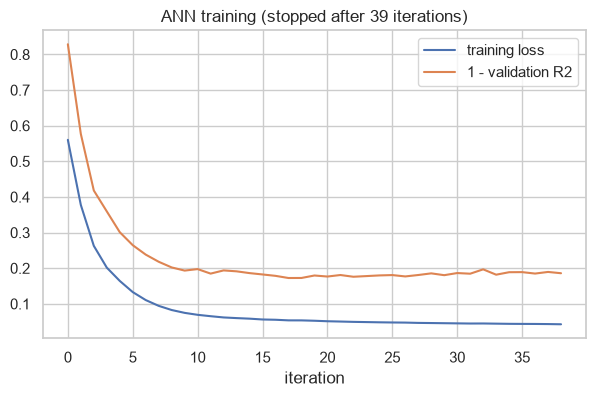

In [5]:
mlp = hyb.ann_.regressor_.named_steps["model"]
plt.figure(figsize=(7, 4))
plt.plot(mlp.loss_curve_, label="training loss")
if getattr(mlp, "validation_scores_", None) is not None:
    plt.plot(1 - np.array(mlp.validation_scores_), label="1 - validation R2")
plt.xlabel("iteration"); plt.legend(); plt.title(f"ANN training (stopped after {mlp.n_iter_} iterations)")
plt.savefig(config.PLOT_DIR / "06_ann_training_curve.png", dpi=150); plt.show()

## Weight experiment (validation set)

In [6]:
rows = []
for w in np.round(np.arange(0.1, 1.0, 0.1), 1):
    m = regression_metrics(y_va, w * p_rf + (1 - w) * p_ann)
    rows.append({"RF weight": w, "ANN weight": round(1 - w, 1), "validation MAE": m["MAE"], "validation RMSE": m["RMSE"], "validation R2": m["R2"]})
wt = pd.DataFrame(rows)
best_w = float(wt.sort_values("validation MAE").iloc[0]["RF weight"])
print("best RF weight:", best_w)
wt

best RF weight: 0.8


,RF weight,ANN weight,validation MAE,validation RMSE,validation R2
0,0.10,0.90,"18,657.96","36,261.43",0.86
1,0.20,0.80,"18,193.92","35,449.79",0.86
2,0.30,0.70,"17,786.04","34,764.58",0.87
3,0.40,0.60,"17,443.44","34,213.39",0.87
4,0.50,0.50,"17,177.04","33,802.78",0.88
5,0.60,0.40,"16,994.86","33,537.91",0.88
6,0.70,0.30,"16,887.84","33,422.26",0.88
7,0.80,0.20,"16,873.99","33,457.36",0.88
8,0.90,0.10,"16,928.11","33,642.75",0.88


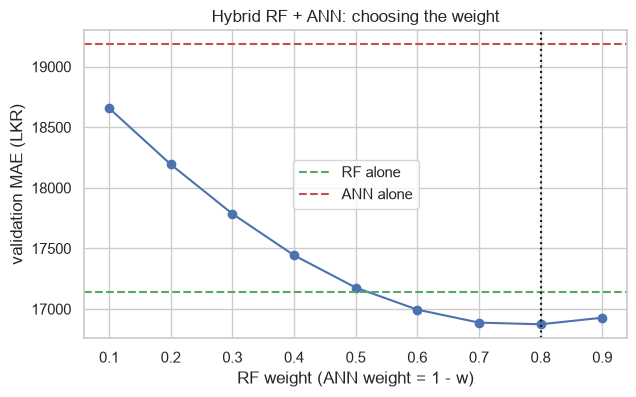

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(wt["RF weight"], wt["validation MAE"], marker="o")
plt.axhline(regression_metrics(y_va, p_rf)["MAE"], ls="--", c="g", label="RF alone")
plt.axhline(regression_metrics(y_va, p_ann)["MAE"], ls="--", c="r", label="ANN alone")
plt.axvline(best_w, ls=":", c="k"); plt.xlabel("RF weight (ANN weight = 1 - w)"); plt.ylabel("validation MAE (LKR)")
plt.legend(); plt.title("Hybrid RF + ANN: choosing the weight")
plt.savefig(config.PLOT_DIR / "06_hybrid_weights.png", dpi=150); plt.show()

In [8]:
p_h = best_w * p_rf + (1 - best_w) * p_ann
pd.Series(regression_metrics(y_va, p_h), name=f"Hybrid w_RF={best_w} (validation)").to_frame()

,Hybrid w_RF=0.8 (validation)
MAE,"16,873.99"
RMSE,"33,457.36"
R2,0.88
MAPE_%,29.37
MedianAE,"8,017.64"


## Notes

- **Hybrid performance:** The hybrid model (80% RF + 20% ANN) performed best, achieving an MAE of Rs. 16,874 and R² of 0.88, slightly better than both RF and ANN alone.
- **Why hybrid works:** Random Forest and ANN learn patterns differently. Combining their predictions helps reduce errors. The higher RF weight reflects its stronger individual performance.
- **Weight sensitivity:** Weights between 0.7 and 0.9 produced similar results, showing that performance is not highly sensitive to the exact weight.